<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

贵州茅台酒股份有限公司：成立于1999年11月20日，由中国贵州茅台酒厂（集团）有限责任公司作为主发起人联合其他七家单位共同发起设立，目前控股股东为茅台集团。公司总部位于贵州省北部赤水河畔的茅台镇，主营茅台酒及茅台酱香系列酒的生产与销售，主导产品“贵州茅台酒”是我国大曲酱香型白酒的鼻祖和典型代表，集国家地理标志产品、有机食品和国家非物质文化遗产于一身。

公司于2001年8月27日在上海证券交易所上市交易。上市以来，截至2026年6月30日，公司累计现金分红总额达4011.45亿元，为IPO募资净额的200.77倍。据“BrandZ最具价值全球品牌排行榜”显示，2026年贵州茅台品牌价值达736.30亿美元，是全球最具价值的酒类品牌。

# 第二部分：研究问题题目及其内涵介绍

贵州茅台的市盈率（PE-TTM）历史分位数能否预测其未来收益率？低估值区间是否对应更高的后续回报？
本研究以贵州茅台为样本，用Tushare获取2020-2025年的日线行情与每日估值数据，计算PE-TTM的滚动历史分位数，检验"低估值分位→高后续收益"这一规律在茅台身上是否成立。具体来说，需要回答三个层次的问题：
相关性层面：PE历史分位数与未来收益率之间是否存在负相关关系？即PE越高，未来收益是否越低？分组层面：将PE分位数按高低分组后，低分位组的未来收益是否显著高于高分位组？稳健性层面：这一规律是否依赖于单一估值指标？改用PB分位数做交叉验证，结论是否一致？
为什么选择贵州茅台:贵州茅台是A股"核心资产"的典型代表，市场长期给予其较高估值，理由是"业绩确定性高、品牌壁垒强、未来增长可期"。如果沃顿论文的结论在茅台身上也成立，那么高PE可能更多反映的是未来的低回报，而非高增长。这个检验不仅具有学术意义，也能为理解A股核心资产的定价逻辑提供实证参考。

# 第三部分：数据采集

#数据采集

In [8]:
import tushare as ts
import pandas as pd
import numpy as np

# 为了批改方便，这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

# ==================== 参数设置 ====================
ts_code = '600519.SH'      # 贵州茅台
start_date = '20200101'
end_date = '20251231'

# ==================== 采集1：日线行情（前复权）====================
df_price = ts.pro_bar(
    ts_code=ts_code,
    adj='qfq',
    start_date=start_date,
    end_date=end_date
)

if df_price is None or df_price.empty:
    raise ValueError("行情数据为空,请检查token权限或股票代码")

df_price = df_price[['trade_date', 'close']].copy()
df_price['trade_date'] = pd.to_datetime(df_price['trade_date'], format='%Y%m%d')

# ==================== 采集2：每日估值指标 ====================
df_basic = pro.daily_basic(
    ts_code=ts_code,
    start_date=start_date,
    end_date=end_date,
    fields='trade_date,close,total_mv,pe_ttm,pb'
)

if df_basic is None or df_basic.empty:
    raise ValueError("估值数据为空,请确认账号是否达到daily_basic接口的2000积分要求")

df_basic['trade_date'] = pd.to_datetime(df_basic['trade_date'], format='%Y%m%d')

# ==================== 合并数据（显式重命名，避免列名冲突）====================
df_price_use = df_price.rename(columns={'close': 'close_price'})
df_basic_use = df_basic[['trade_date', 'pe_ttm', 'pb', 'total_mv']].copy()

df = pd.merge(
    df_price_use,
    df_basic_use,
    on='trade_date',
    how='inner'
)
df = df.sort_values('trade_date').reset_index(drop=True)

# ==================== 转为月度数据 ====================
# 每月取最后一个交易日，与估值指标的月度频率对齐
df['year_month'] = df['trade_date'].dt.to_period('M')
df_monthly = df.groupby('year_month').last().reset_index()
df_monthly['trade_date'] = df_monthly['trade_date'].astype(str)

# ==================== 数据采集结果输出 ====================
print("=" * 60)
print("数据采集完成")
print("=" * 60)
print(f"合并后的列名：{df.columns.tolist()}")
print(f"数据范围：{df['trade_date'].min().date()} 至 {df['trade_date'].max().date()}")
print(f"总交易日数：{len(df)}")
print(f"pe_ttm缺失值数量:{df['pe_ttm'].isna().sum()}")
print(f"月度观测数：{len(df_monthly)}")

print("\n日频数据前5行:")
print(df.head())

print("\n月度数据前5行:")
print(df_monthly[['trade_date', 'close_price', 'pe_ttm', 'pb']].head())

print("\n月度数据后5行:")
print(df_monthly[['trade_date', 'close_price', 'pe_ttm', 'pb']].tail())

数据采集完成
合并后的列名：['trade_date', 'close_price', 'pe_ttm', 'pb', 'total_mv', 'year_month']
数据范围：2020-01-02 至 2025-12-31
总交易日数：1455
pe_ttm缺失值数量：0
月度观测数：72

日频数据前5行：
  trade_date  close_price   pe_ttm       pb      total_mv year_month
0 2020-01-02       979.17  34.6855  11.3326  1.419504e+08    2020-01
1 2020-01-03       934.60  33.1066  10.8167  1.354885e+08    2020-01
2 2020-01-06       934.10  33.0891  10.8110  1.354169e+08    2020-01
3 2020-01-07       948.44  33.5968  10.9769  1.374946e+08    2020-01
4 2020-01-08       942.90  33.4006  10.9128  1.366919e+08    2020-01

月度数据前5行：
   trade_date  close_price   pe_ttm       pb
0  2020-01-23       912.28  32.3159  10.5584
1  2020-02-28       915.91  32.4448  10.6005
2  2020-03-31       962.71  34.1023  11.1421
3  2020-04-30      1096.76  36.9084  10.6635
4  2020-05-29      1184.19  39.8507  11.5136

月度数据后5行：
    trade_date  close_price   pe_ttm      pb
67  2025-08-29      1455.22  20.6723  7.7905
68  2025-09-30      1419.82  20.1063  7.7726
69

# 第四部分：数据分析过程

步骤1：有效分析样本
有效分析样本数：36
分析区间：2022-12-30 至 2025-11-28
    trade_date   pe_ttm   pe_rank   pb_rank  ret_fwd_1m
61  2025-02-28  22.8007  0.083333  0.250000    0.040116
62  2025-03-31  23.7155  0.250000  0.361111   -0.008968
63  2025-04-30  21.8327  0.055556  0.027778   -0.016161
64  2025-05-30  21.4799  0.027778  0.027778   -0.055758
65  2025-06-30  19.8925  0.027778  0.083333    0.008622
66  2025-07-31  20.0639  0.055556  0.111111    0.041027
67  2025-08-29  20.6723  0.083333  0.083333   -0.024326
68  2025-09-30  20.1063  0.083333  0.083333   -0.009684
69  2025-10-31  19.8913  0.027778  0.027778    0.014331
70  2025-11-28  20.1763  0.138889  0.055556   -0.034385

步骤2：按PE分位数中位数分组的未来收益率统计
          样本数  未来1月均值  未来1月中位数  未来3月均值  未来6月均值      胜率
pe_group                                              
低分位        23  0.0091   0.0086  0.0163 -0.0095  0.5217
高分位        13 -0.0211  -0.0179 -0.0583 -0.0406  0.3077

步骤3：PE分位数与未来收益率的相关性
PE分位数与未来1月收益率相关系数：-0.1814
PE分位数与未来3月收益率相关系数：-0.4518

=== 低分位组 vs 高分

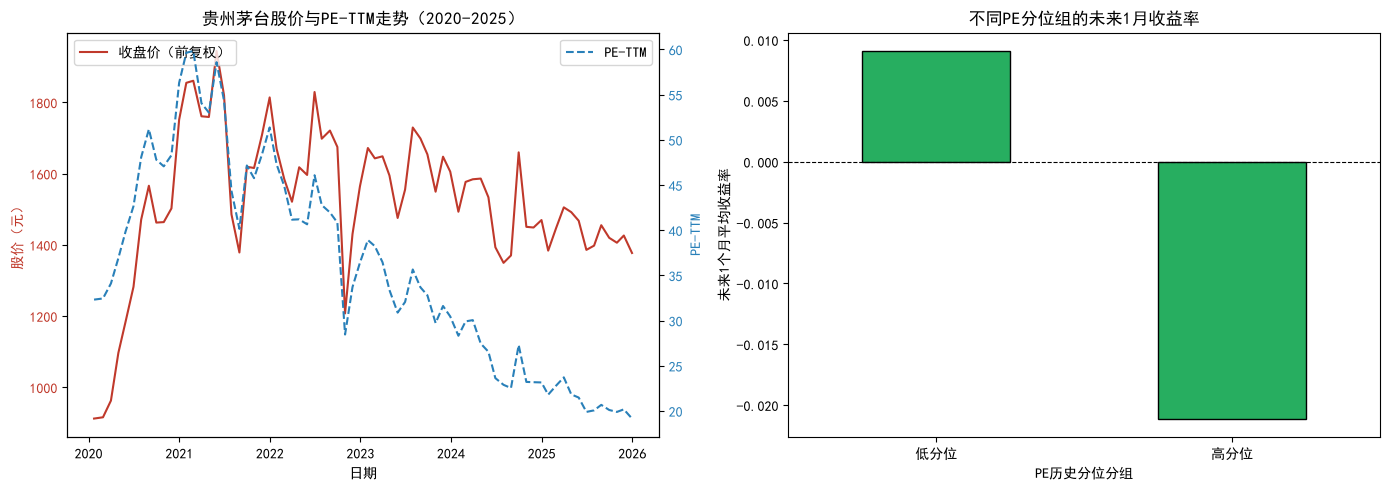

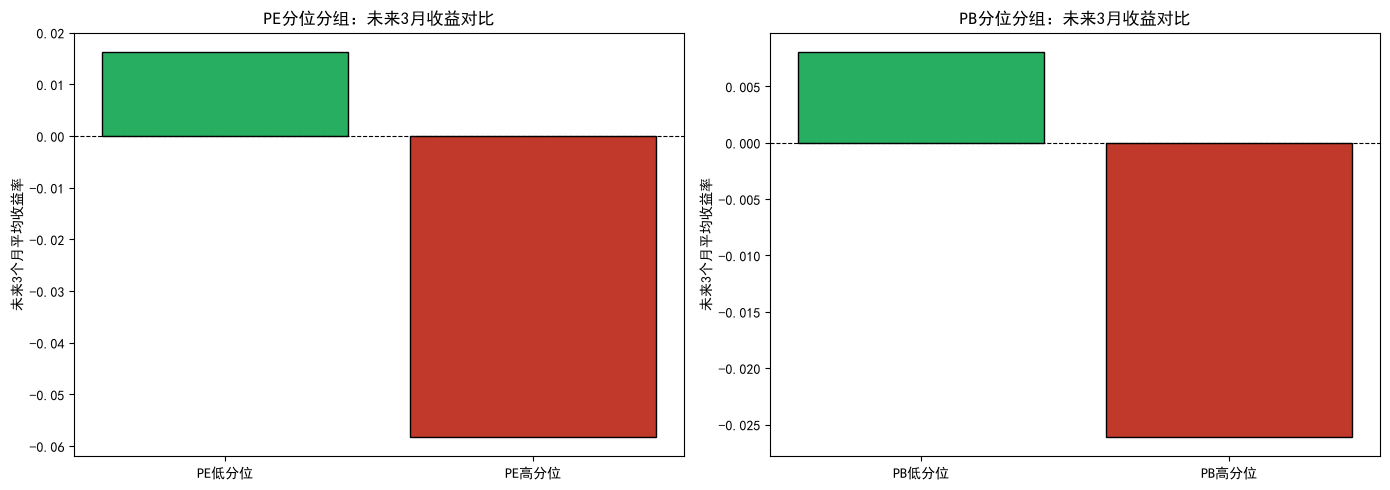


步骤5：PE vs PB 稳健性汇总对比
指标  与未来1月收益相关系数  与未来3月收益相关系数  低分位未来3月收益  高分位未来3月收益  收益差（低-高）
PE      -0.1814      -0.4518     0.0163    -0.0583    0.0745
PB      -0.0845      -0.2834     0.0081    -0.0261    0.0342

步骤6：分析结论

1. 相关性：PE分位数与未来3月收益率相关系数为-0.4518，呈中等偏强负相关，
   说明PE越高，未来收益越低。3月相关性（-0.45）明显强于1月（-0.18），
   表明估值消化需要时间，中期预测力更强。

2. 分组：低分位组未来3月平均收益+1.63%，高分位组-5.83%，
   收益差7.45个百分点；低分位组胜率52.17%，高分位组30.77%。

3. 稳健性：PB分位数结论方向一致（低分位+0.81%，高分位-2.61%，
   收益差3.42%），说明结论不依赖单一估值指标。PE预测力强于PB，
   可能与茅台轻资产、高ROE特征有关。

4. 与沃顿论文呼应：高PE对应低后续回报，支持"低估值预示高回报"的结论，
   说明茅台估值存在均值回归特征。

5. 局限：有效样本仅36个，单只股票，结论不能直接推广到全市场。



In [9]:
import matplotlib.pyplot as plt

# 中文字体设置
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ---------- 1. 计算滚动分位数（PE和PB）----------
# 使用过去36个月滚动窗口，计算当前估值在窗口内的百分位
df_monthly['pe_rank'] = df_monthly['pe_ttm'].rolling(36).apply(
    lambda x: pd.Series(x).rank(pct=True).iloc[-1]
)
df_monthly['pb_rank'] = df_monthly['pb'].rolling(36).apply(
    lambda x: pd.Series(x).rank(pct=True).iloc[-1]
)

# ---------- 2. 计算未来收益率 ----------
df_monthly['ret_fwd_1m'] = df_monthly['close_price'].shift(-1) / df_monthly['close_price'] - 1
df_monthly['ret_fwd_3m'] = df_monthly['close_price'].shift(-3) / df_monthly['close_price'] - 1
df_monthly['ret_fwd_6m'] = df_monthly['close_price'].shift(-6) / df_monthly['close_price'] - 1

# 删除滚动窗口不足导致的缺失值
df_analysis = df_monthly.dropna(subset=['pe_rank', 'ret_fwd_1m']).copy()

print("=" * 60)
print("步骤1:有效分析样本")
print("=" * 60)
print(f"有效分析样本数：{len(df_analysis)}")
print(f"分析区间：{df_analysis['trade_date'].min()} 至 {df_analysis['trade_date'].max()}")
print(df_analysis[['trade_date', 'pe_ttm', 'pe_rank', 'pb_rank', 'ret_fwd_1m']].tail(10))

# ---------- 3. 按PE分位数中位数分2组 ----------
median_rank = df_analysis['pe_rank'].median()
df_analysis['pe_group'] = np.where(
    df_analysis['pe_rank'] <= median_rank, '低分位', '高分位'
)

group_stats = df_analysis.groupby('pe_group', observed=True).agg(
    样本数=('ret_fwd_1m', 'count'),
    未来1月均值=('ret_fwd_1m', 'mean'),
    未来1月中位数=('ret_fwd_1m', 'median'),
    未来3月均值=('ret_fwd_3m', 'mean'),
    未来6月均值=('ret_fwd_6m', 'mean'),
    胜率=('ret_fwd_1m', lambda x: (x > 0).mean())
).round(4)

print("\n" + "=" * 60)
print("步骤2:按PE分位数中位数分组的未来收益率统计")
print("=" * 60)
print(group_stats)

# ---------- 4. 相关性检验（PE）----------
corr_1m = df_analysis['pe_rank'].corr(df_analysis['ret_fwd_1m'])
corr_3m = df_analysis['pe_rank'].corr(df_analysis['ret_fwd_3m'])

print("\n" + "=" * 60)
print("步骤3:PE分位数与未来收益率的相关性")
print("=" * 60)
print(f"PE分位数与未来1月收益率相关系数:{corr_1m:.4f}")
print(f"PE分位数与未来3月收益率相关系数:{corr_3m:.4f}")

# ---------- 5. 低分位 vs 高分位对比 ----------
low = df_analysis[df_analysis['pe_group'] == '低分位']['ret_fwd_3m'].dropna()
high = df_analysis[df_analysis['pe_group'] == '高分位']['ret_fwd_3m'].dropna()

print("\n=== 低分位组 vs 高分位组(未来3月收益)===")
print(f"低分位组：样本{len(low)}个，平均收益{low.mean():.4f}，中位数{low.median():.4f}")
print(f"高分位组：样本{len(high)}个，平均收益{high.mean():.4f}，中位数{high.median():.4f}")
print(f"收益差（低-高）：{low.mean() - high.mean():.4f}")

# ---------- 6. 稳健性检验（PB）----------
print("\n" + "=" * 60)
print("步骤4:PB分位数稳健性检验")
print("=" * 60)

corr_pb_1m = df_analysis['pb_rank'].corr(df_analysis['ret_fwd_1m'])
corr_pb_3m = df_analysis['pb_rank'].corr(df_analysis['ret_fwd_3m'])
print(f"PB分位数与未来1月收益率相关系数:{corr_pb_1m:.4f}")
print(f"PB分位数与未来3月收益率相关系数:{corr_pb_3m:.4f}")

median_pb = df_analysis['pb_rank'].median()
df_analysis['pb_group'] = np.where(
    df_analysis['pb_rank'] <= median_pb, 'PB低分位', 'PB高分位'
)

pb_group_stats = df_analysis.groupby('pb_group', observed=True).agg(
    样本数=('ret_fwd_1m', 'count'),
    未来1月均值=('ret_fwd_1m', 'mean'),
    未来3月均值=('ret_fwd_3m', 'mean'),
    未来6月均值=('ret_fwd_6m', 'mean'),
    胜率=('ret_fwd_1m', lambda x: (x > 0).mean())
).round(4)

print("\n=== 按PB分位数中位数分组的未来收益率统计 ===")
print(pb_group_stats)

pb_low = df_analysis[df_analysis['pb_group'] == 'PB低分位']['ret_fwd_3m'].dropna()
pb_high = df_analysis[df_analysis['pb_group'] == 'PB高分位']['ret_fwd_3m'].dropna()
print(f"\nPB低分位组未来3月平均收益:{pb_low.mean():.4f}")
print(f"PB高分位组未来3月平均收益:{pb_high.mean():.4f}")
print(f"收益差（低-高）：{pb_low.mean() - pb_high.mean():.4f}")

# ---------- 7. 可视化：股价与PE走势 ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.plot(pd.to_datetime(df_monthly['trade_date']), df_monthly['close_price'],
         color='#c0392b', linewidth=1.5, label='收盘价（前复权）')
ax1.set_xlabel('日期')
ax1.set_ylabel('股价（元）', color='#c0392b')
ax1.tick_params(axis='y', labelcolor='#c0392b')

ax2 = ax1.twinx()
ax2.plot(pd.to_datetime(df_monthly['trade_date']), df_monthly['pe_ttm'],
         color='#2980b9', linewidth=1.5, linestyle='--', label='PE-TTM')
ax2.set_ylabel('PE-TTM', color='#2980b9')
ax2.tick_params(axis='y', labelcolor='#2980b9')
ax1.set_title('贵州茅台股价与PE-TTM走势(2020-2025)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

ax3 = axes[1]
group_stats['未来1月均值'].plot(kind='bar', ax=ax3, color='#27ae60', edgecolor='black')
ax3.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax3.set_xlabel('PE历史分位分组')
ax3.set_ylabel('未来1个月平均收益率')
ax3.set_title('不同PE分位组的未来1月收益率')
ax3.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# ---------- 8. 可视化：PE vs PB稳健性对比 ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
pe_low_3m = df_analysis[df_analysis['pe_group'] == '低分位']['ret_fwd_3m'].mean()
pe_high_3m = df_analysis[df_analysis['pe_group'] == '高分位']['ret_fwd_3m'].mean()
ax1.bar(['PE低分位', 'PE高分位'], [pe_low_3m, pe_high_3m],
        color=['#27ae60', '#c0392b'], edgecolor='black')
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax1.set_ylabel('未来3个月平均收益率')
ax1.set_title('PE分位分组:未来3月收益对比')

ax2 = axes[1]
pb_low_3m = pb_low.mean()
pb_high_3m = pb_high.mean()
ax2.bar(['PB低分位', 'PB高分位'], [pb_low_3m, pb_high_3m],
        color=['#27ae60', '#c0392b'], edgecolor='black')
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.set_ylabel('未来3个月平均收益率')
ax2.set_title('PB分位分组:未来3月收益对比')

plt.tight_layout()
plt.show()

# ---------- 9. 汇总对比表 ----------
print("\n" + "=" * 60)
print("步骤5:PE vs PB 稳健性汇总对比")
print("=" * 60)
summary = pd.DataFrame({
    '指标': ['PE', 'PB'],
    '与未来1月收益相关系数': [corr_1m, corr_pb_1m],
    '与未来3月收益相关系数': [corr_3m, corr_pb_3m],
    '低分位未来3月收益': [low.mean(), pb_low.mean()],
    '高分位未来3月收益': [high.mean(), pb_high.mean()],
    '收益差（低-高）': [low.mean()-high.mean(), pb_low.mean()-pb_high.mean()]
}).round(4)
print(summary.to_string(index=False))

# ---------- 10. 分析结论文字输出 ----------
print("\n" + "=" * 60)
print("步骤6:分析结论")
print("=" * 60)
print("""
1. 相关性:PE分位数与未来3月收益率相关系数为-0.4518,呈中等偏强负相关，
   说明PE越高,未来收益越低。3月相关性(-0.45)明显强于1月(-0.18),
   表明估值消化需要时间，中期预测力更强。

2. 分组:低分位组未来3月平均收益+1.63%，高分位组-5.83%,
   收益差7.45个百分点:低分位组胜率52.17%,高分位组30.77%。

3. 稳健性:PB分位数结论方向一致(低分位+0.81%，高分位-2.61%,
   收益差3.42%),说明结论不依赖单一估值指标。PE预测力强于PB,
   可能与茅台轻资产、高ROE特征有关。

4. 与沃顿论文呼应:高PE对应低后续回报,支持"低估值预示高回报"的结论，
   说明茅台估值存在均值回归特征。

5. 局限:有效样本仅36个,单只股票,结论不能直接推广到全市场。
""")

# 第五部分：研究结论与经验总结

## 研究结论

本研究以贵州茅台（600519.SH）为样本，检验了PE-TTM历史分位数对未来收益率的预测能力。样本期为2020年1月至2025年12月，经滚动36个月窗口处理后，有效分析区间为2022年12月至2025年11月，共36个月度观测。
1.PE分位数与未来收益率呈显著负相关。 PE分位数与未来1月收益率的相关系数为 -0.1814，与未来3月收益率的相关系数为 -0.4518。3个月的相关性明显强于1个月（绝对值约为2.5倍），说明估值消化需要时间，估值对中期收益的预测力更强。
2.低估值分位对应更高的后续回报。按PE分位数中位数分组后：低分位组未来3月平均收益 +1.63%，高分位组 -5.83%，收益差达7.45个百分点；低分位组胜率52.17%，高分位组仅30.77%，差异21.4个百分点。这一差异在经济意义上显著。
3.稳健性检验通过。 改用PB分位数做交叉验证，结论方向完全一致：PB分位数同样呈负相关，低分位组收益为正、高分位组为负。但PB的相关系数绝对值小于PE（-0.28 vs -0.45），说明PE的预测力更强，可能与茅台轻资产、高ROE的特征有关——PB的账面价值对估值的指示意义较弱。
4.与沃顿论文的呼应。 沃顿商学院2023年论文发现，市盈率差异的75%体现在未来回报差异上，仅25%体现在盈利增长上。本研究从个股层面验证了这一方向：茅台的高PE并未带来更高的后续盈利增长（否则股价应继续上涨），反而对应了更低的后续回报。这说明市场对茅台的高估值定价中，包含了对未来回报的压低，而非对未来高增长的合理预期，估值存在均值回归特征。
对研究问题的回答：贵州茅台的PE-TTM历史分位数确实能预测其未来收益率，低估值区间对应更高的后续回报。数据支持"低估值预示高回报"的假设。

## 经验总结

1.数据分析不等于数据收集，写代码时要把这两个部分分开，不然会得到重复性结果。
2.进行数据分析，要保证数据的完整性与有效性，同时需要把握采集的数据的时间区间：时间太短，短期波动误判估值的高低。茅台的估值中枢本身会随市场环境变化，2021年茅台PE可以到60倍，2025年只有20倍。如果用12个月窗口，2025年的20倍PE在“最近12个月”里可能已经算高了，但实际上放在更长历史里看，它仍是低位；时间太长，历史信息会稀释当前估值的指示意义。有的历史数据与当前市场环境差异太大，会把参照系拉偏。
3.数据分析最后最好生成相关图像或者表格，否则，一堆文字不易进行解读、再次分析。
4.有些结论并不是对于所有的企业、产业都是适用的，比如这个结论对茅台适用，但是保险、金融行业就不行。“风险”有时可能是“机遇”，但有时的确是“危险信号”。